## SVM for the Climate Model Simulation Crashes Data

*by Zachary Porter*

In this project, I aim to find and train the best model for predicting climate simulation crashes. These simulation crashes typically occur due to unstable parameters, and my goal is to identify the best model to predict which simulations will crash.

My data set consists of 540 simulations, each described by 18 scaled numerical parameters. Each simulation has a binary outcome: 0 for failure and 1 for success. Predicting crashes saves time and resources.

I developed and compared multiple kernels with hyperparameter tuning to find the best fitting Support Vector Machine (SVM) model.

## I use the following libraries:

**numpy** -- For calculations on data

**pandas** -- To load and analyse the data set

**matplot** -- For plotting data

**seaborn** -- To improve the formatting of our graphs

**sklearn.model_selection**: train_test_split -- To split our data into training and test data sets

**sklearn.metrics**: accuracy_score, classification_report, confusion_matrix -- For crafting summaries for comparison across multiple models

**sklearn.svm** -- Used to construct our kernels

**sklearn.model_selection**: GridSearchCV -- To build a Grid Search for the Tuning of the RBF kernel


*Data was loaded via google_colab's drive*

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from google.colab import drive
drive.mount('/content/drive')

PATHNAME = '/content/drive/MyDrive/colab_data/'
FILENAME = 'pop_failures.dat'

complete_path = PATHNAME + FILENAME
data = pd.read_csv(complete_path, delim_whitespace=True, header=0)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_1296/2579498652.py:17: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(complete_path, delim_whitespace=True, header=0)


# Data Cleanup and Examination

From the code below, one might notice these data are complete; each simulation includes information on all 18 parameters, including an outcome.

Most of the parameters are of the float64 data type, which seems correct; the outcome feature was represented as an int64 and was changed to a boolean data type to better represent its discrete nature.

Furthermore, the data was examined for duplicate values, none of which exist, using an if-statement to check for their presence; if any exist, the program removes them from our data set.

Finally, the 'Run' and 'Study' columns were removed from the data set because they are not important to achieve our goal.

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Study                 540 non-null    int64  
 1   Run                   540 non-null    int64  
 2   vconst_corr           540 non-null    float64
 3   vconst_2              540 non-null    float64
 4   vconst_3              540 non-null    float64
 5   vconst_4              540 non-null    float64
 6   vconst_5              540 non-null    float64
 7   vconst_7              540 non-null    float64
 8   ah_corr               540 non-null    float64
 9   ah_bolus              540 non-null    float64
 10  slm_corr              540 non-null    float64
 11  efficiency_factor     540 non-null    float64
 12  tidal_mix_max         540 non-null    float64
 13  vertical_decay_scale  540 non-null    float64
 14  convect_corr          540 non-null    float64
 15  bckgrnd_vdc1          5

In [ ]:
# Change the datatype of 'outcome' from int64 to bool
if data['outcome'].dtype != 'bool':
  data['outcome'] = data['outcome'].astype(bool)

# Check for duplicates and drop from data
if data.duplicated().sum() >= 1:
  data.drop_duplicates(inplace=True)

# Checking for NaN values and remove any rows that contain NaN values
if (data.isna().sum() >= 1).any():
  data.dropna(inplace=True)

  # Checking for Null Values
  data.isnull().sum()


if 'Study' in data and 'Run' in data:
  data.drop(columns=['Study', 'Run'], inplace=True)

# Verify the removal of 'Run' and 'Study' and the conversion of
# the 'outcome' column to data type bool.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vconst_corr           540 non-null    float64
 1   vconst_2              540 non-null    float64
 2   vconst_3              540 non-null    float64
 3   vconst_4              540 non-null    float64
 4   vconst_5              540 non-null    float64
 5   vconst_7              540 non-null    float64
 6   ah_corr               540 non-null    float64
 7   ah_bolus              540 non-null    float64
 8   slm_corr              540 non-null    float64
 9   efficiency_factor     540 non-null    float64
 10  tidal_mix_max         540 non-null    float64
 11  vertical_decay_scale  540 non-null    float64
 12  convect_corr          540 non-null    float64
 13  bckgrnd_vdc1          540 non-null    float64
 14  bckgrnd_vdc_ban       540 non-null    float64
 15  bckgrnd_vdc_eq        5

# Exploratory Data Analysis

The code below is concerned with analysis. I will begin with a descriptive summary of the data using the 'describe' function to display general statistics for the dataset. From this summary, it can be seen that each parameter has consistent counts, with no missing values. Each parameter is centered around ~0.5 for its mean and ~0.28 for its standard deviation, indicating normality.

Next, I will draw a count plot to visualize the proportions of failures vs. outcomes. It displays an imbalance, with only 46 failures and 494 successes. This is important to note, as it will affect how to interpret the results, particularly in cases of failure detection.

A heatmap is drawn to visualize the correlations between variables. This will help identify which features might be meaningfully related to the target variable. From the graph, it can be seen that the following variables have ***some*** importance: bckgrnd_vdc1, bckgrnd_vdc_eq, bckgrnd_vdc_ban, and vconst_4-7.

In [ ]:
# Displays descriptive summary of the data
df = pd.DataFrame(data)
data.describe()

,vconst_corr,vconst_2,vconst_3,vconst_4,vconst_5,vconst_7,ah_corr,ah_bolus,slm_corr,efficiency_factor,tidal_mix_max,vertical_decay_scale,convect_corr,bckgrnd_vdc1,bckgrnd_vdc_ban,bckgrnd_vdc_eq,bckgrnd_vdc_psim,Prandtl
count,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000,540.000000
mean,0.500026,0.500097,0.500027,0.500119,0.500001,0.499913,0.500059,0.500076,0.500044,0.500111,0.499984,0.500032,0.499933,0.499944,0.499946,0.500044,0.500020,0.500021
std,0.288939,0.288922,0.289067,0.288993,0.288827,0.288852,0.289010,0.288909,0.288860,0.288966,0.289127,0.289014,0.288822,0.288949,0.288923,0.288813,0.288936,0.289013
min,0.000414,0.001922,0.001181,0.001972,0.000858,0.000476,0.004590,0.000296,0.003231,0.002015,0.000419,0.001188,0.001312,0.002509,0.000732,0.000891,0.000219,0.000263
25%,0.249650,0.251597,0.251540,0.250158,0.250630,0.251325,0.253048,0.250402,0.252661,0.250758,0.251676,0.249669,0.249988,0.249586,0.249974,0.250412,0.252739,0.249723
50%,0.499998,0.499595,0.500104,0.500456,0.500903,0.499174,0.499070,0.500074,0.500295,0.500393,0.500322,0.500151,0.500625,0.499080,0.499959,0.500384,0.498955,0.499431
75%,0.750042,0.750011,0.749180,0.750348,0.748988,0.748166,0.750109,0.749091,0.748605,0.749447,0.749346,0.749164,0.749569,0.750012,0.747978,0.749256,0.748539,0.749792
max,0.999194,0.998815,0.998263,0.997673,0.998944,0.997142,0.998930,0.998506,0.997172,0.999536,0.999942,0.997718,0.997518,0.999795,0.999155,0.997265,0.999306,0.999655


In [ ]:
# Display a count of each outcome
df["outcome"].value_counts()

,count
outcome,
True,494
False,46


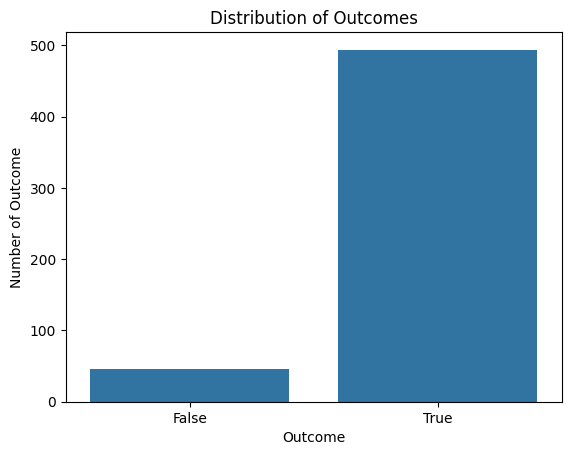

In [ ]:
# Create a simple bar graph to display the distribution of outcomes
sns.countplot(x='outcome', data=data)
plt.ylabel("Number of Outcome")
plt.xlabel("Outcome")
plt.title("Distribution of Outcomes")

plt.show()

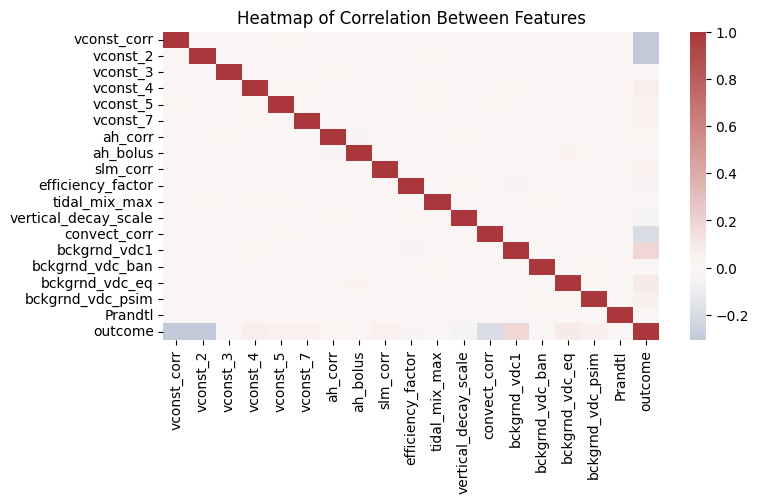

In [ ]:
# Draw a heatmap to the screen to investigate how variables relate to eachother
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(), center=0, cmap='vlag')
plt.title("Heatmap of Correlation Between Features")

plt.show()


# Building Our Models

I begin by splitting the data into training (2/3) and testing (1/3) sets, and printing the shapes of the new sets to validate.

Next, I define a model dictionary to store the desired kernels. At first, I only tested the linear kernel, finding that while it is accurate, it does not effectively identify failure classifications, as seen in the low recall. This is most likely due to an imbalance in the data set's proportions.

Continuing with the inclusion of more kernels: Polynomial, RBF, and Sigmoid. From the new results, we can see that all kernels are nearly as accurate as the linear model, with the polynomial SVM surpassing the linear SVM's accuracy by ~1%.

Further investigation shows that the polynomial model performed best overall, with a good balance among precision, recall, and F1-score for both success and failure detection.

In [ ]:
# Remove the 'outcome' column for X
X = data.drop('outcome', axis=1)
y = data['outcome']

# Set up the data split for training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.33,
    random_state = 42,
    stratify = y
)

print("X train shape: ", X_train.shape)
print("X test shape: ", X_test.shape)

X train shape:  (361, 18)
X test shape:  (179, 18)


In [ ]:
# Initialize the models dictionary
models = { "Linear SVM": SVC(kernel="linear") }

# Get the results of the Linear SVM
results = []
models['Linear SVM'].fit(X_train, y_train)
y_pred = models['Linear SVM'].predict(X_test)

acc = accuracy_score(y_test, y_pred)

results.append({
  "Model": 'Linear SVM',
  "Accuracy": acc
})

print("Accuracy: \n", results)
print("\nConfusion Matrix: \n", confusion_matrix(y_test, y_pred))
print("\nClassification Report: \n\n", classification_report(y_test, y_pred))


Accuracy: 
 [{'Model': 'Linear SVM', 'Accuracy': 0.9329608938547486}]

Confusion Matrix: 
 [[  3  12]
 [  0 164]]

Classification Report: 

               precision    recall  f1-score   support

       False       1.00      0.20      0.33        15
        True       0.93      1.00      0.96       164

    accuracy                           0.93       179
   macro avg       0.97      0.60      0.65       179
weighted avg       0.94      0.93      0.91       179



In [ ]:
# Redefine models to include all models
models = {
    "Linear SVM": SVC(kernel="linear"),
    "Polynomial SVM": SVC(kernel="poly"),
    "RBF SVM": SVC(kernel="rbf"),
    "Sigmoid SVM": SVC(kernel="sigmoid")
  }

# Redefine results as an empty array
results = []

# Loop through models and capture results
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc
    })

# Display results of model tests
results_df = pd.DataFrame(results)
results_df.sort_values(by="Accuracy", ascending=False, inplace=True)
results_df

,Model,Accuracy
1,Polynomial SVM,0.944134
0,Linear SVM,0.932961
2,RBF SVM,0.916201
3,Sigmoid SVM,0.899441


In [ ]:
# Loop to display confusion matrices for all models with accuracy
for name, model in models.items():
    print(f"\n--- Evaluating {name} ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    print(f"Accuracy: {acc:.4f}\n")
    print("\nConfusion Matrix:\n\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n\n", classification_report(y_test, y_pred, zero_division=0))


--- Evaluating Linear SVM ---
Accuracy: 0.9330


Confusion Matrix:

 [[  3  12]
 [  0 164]]

Classification Report:

               precision    recall  f1-score   support

       False       1.00      0.20      0.33        15
        True       0.93      1.00      0.96       164

    accuracy                           0.93       179
   macro avg       0.97      0.60      0.65       179
weighted avg       0.94      0.93      0.91       179


--- Evaluating Polynomial SVM ---
Accuracy: 0.9441


Confusion Matrix:

 [[  8   7]
 [  3 161]]

Classification Report:

               precision    recall  f1-score   support

       False       0.73      0.53      0.62        15
        True       0.96      0.98      0.97       164

    accuracy                           0.94       179
   macro avg       0.84      0.76      0.79       179
weighted avg       0.94      0.94      0.94       179


--- Evaluating RBF SVM ---
Accuracy: 0.9162


Confusion Matrix:

 [[  0  15]
 [  0 164]]

Classificatio

# Inclusion of Tuned RBF SVM

This can be taken a step forward by tuning our RBF SVM to improve its performance by using the hyperparameters C and gamma.

Running this test, we can see that it greatly improved the performance of the RBF SVM. It has become better at identifying the failure class and has improved success-class precision by about 0.03. The confusion matrix has a better balance between cases. Overall, the tuned RBF model now ranks among the top models for this data set.

In [ ]:
# Add the tuned RBF model into models
models.update({"Tuned RBF SVM": SVC(kernel="rbf")})

# Define the hyperparameters
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}

# Define a grid search
grid_svm = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_
y_pred_best = best_svm.predict(X_test)

print("Best Parameters:", grid_svm.best_params_)
print("\nConfusion Matrix:\n\n", confusion_matrix(y_test, y_pred_best))
print("\nClassification Report:\n\n", classification_report(y_test, y_pred_best, zero_division=0))

Best Parameters: {'C': 100, 'gamma': 0.1}

Confusion Matrix:

 [[  7   8]
 [  3 161]]

Classification Report:

               precision    recall  f1-score   support

       False       0.70      0.47      0.56        15
        True       0.95      0.98      0.97       164

    accuracy                           0.94       179
   macro avg       0.83      0.72      0.76       179
weighted avg       0.93      0.94      0.93       179



# Conclusion of Tested Models

Of the five models, the polynomial kernel performed the best overall, regardless of the tamperings of others. While the tuned RBF model came close, it still fell short of outperforming the polynomial model in detecting failure cases; however, it was not by much (~7% less on recall).

The other models, RBF (untuned), Linear, and Sigmoid, all performed poorly when tested for failures, with low or nonexistent recall, precision, and F1-scores. For this reason, the polynomial model is the desired solution for this dataset.

In [ ]:
# Frame the data to output neat results
results = []

print("Evaluation Summary of all Models\n\n")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    if name == "Tuned RBF SVM":
      acc = accuracy_score(y_test, y_pred_best)
      report = classification_report(y_test, y_pred_best, output_dict=True, zero_division=0)
    else:
      acc = accuracy_score(y_test, y_pred)
      report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision_true": report.get("True", {}).get("precision", 0),
        "Recall_true": report.get("True", {}).get("recall", 0),
        "F1_true": report.get("True", {}).get("f1-score", 0),
        "Precision_false": report.get("False", {}).get("precision", 0),
        "Recall_false": report.get("False", {}).get("recall", 0),
        "F1_false": report.get("False", {}).get("f1-score", 0),
    })

results_df = pd.DataFrame(results)
results_df.sort_values(by="Accuracy", ascending=False, inplace=True)
results_df

Evaluation Summary of all Models




,Model,Accuracy,Precision_true,Recall_true,F1_true,Precision_false,Recall_false,F1_false
1,Polynomial SVM,0.944134,0.958333,0.981707,0.969880,0.727273,0.533333,0.615385
4,Tuned RBF SVM,0.938547,0.952663,0.981707,0.966967,0.700000,0.466667,0.560000
0,Linear SVM,0.932961,0.931818,1.000000,0.964706,1.000000,0.200000,0.333333
2,RBF SVM,0.916201,0.916201,1.000000,0.956268,0.000000,0.000000,0.000000
3,Sigmoid SVM,0.899441,0.914773,0.981707,0.947059,0.000000,0.000000,0.000000
